In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

w = pd.read_parquet("../data/interim/balance_sheet_wide.parquet")
print(w.shape)
print("Entreprises :", w["cik"].nunique())

(107562, 29)
Entreprises : 13962


In [14]:
# Filtre de taille : exclut les sociétés coquilles et les erreurs d'échelle
avant = len(w)
w = w[w["Assets"] >= 1e6].copy()
print(f"Bilans : {avant:,} → {len(w):,} ({len(w)/avant:.1%})")
print("Entreprises :", w["cik"].nunique())

Bilans : 107,562 → 92,836 (86.3%)
Entreprises : 12219


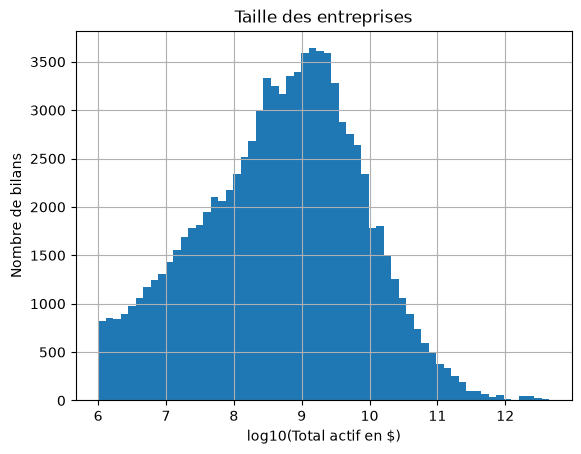

count               92,836
mean        12,134,313,338
std        109,768,179,947
min              1,000,000
1%               1,333,686
25%             73,084,000
50%            605,585,522
75%          3,268,144,500
99%        166,493,500,000
max      4,424,900,000,000
Name: Assets, dtype: str


In [15]:
taille = np.log10(w["Assets"].clip(lower=1))
taille.hist(bins=60)
plt.xlabel("log10(Total actif en $)"); plt.ylabel("Nombre de bilans")
plt.title("Taille des entreprises"); plt.show()

print(w["Assets"].describe(percentiles=[.01, .25, .5, .75, .99]).apply(lambda x: f"{x:,.0f}"))

In [16]:
r = pd.DataFrame({"cik": w["cik"], "end": w["end"]})
r["dettes_actifs"]        = w["Liabilities"] / w["Assets"]
r["capitaux_actifs"]      = w["StockholdersEquity"] / w["Assets"]
r["tresorerie_actifs"]    = w["CashAndCashEquivalentsAtCarryingValue"] / w["Assets"]
r["liquidite_generale"]   = w["AssetsCurrent"] / w["LiabilitiesCurrent"]
r["benef_cumules_actifs"] = w["RetainedEarningsAccumulatedDeficit"] / w["Assets"]

ratios = ["dettes_actifs", "capitaux_actifs", "tresorerie_actifs",
          "liquidite_generale", "benef_cumules_actifs"]
r[ratios].describe(percentiles=[.01, .05, .5, .95, .99]).round(2)

e:\DSI\balance-sheet-scoring\.venv\Lib\site-packages\pandas\core\nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2


,dettes_actifs,capitaux_actifs,tresorerie_actifs,liquidite_generale,benef_cumules_actifs
count,90883.00,84969.00,82958.00,71037.00,84978.00
mean,0.73,0.22,0.17,inf,-2.11
std,5.84,1.69,0.31,NaN,12.18
min,0.00,-104.04,0.00,0.00,-1732.00
1%,0.01,-3.78,0.00,0.02,-37.02
5%,0.06,-0.55,0.00,0.24,-9.80
50%,0.58,0.37,0.08,1.83,-0.02
95%,1.38,0.90,0.72,11.84,0.63
99%,4.11,0.98,0.96,33.43,1.04
max,1510.02,200.16,50.65,inf,78.17


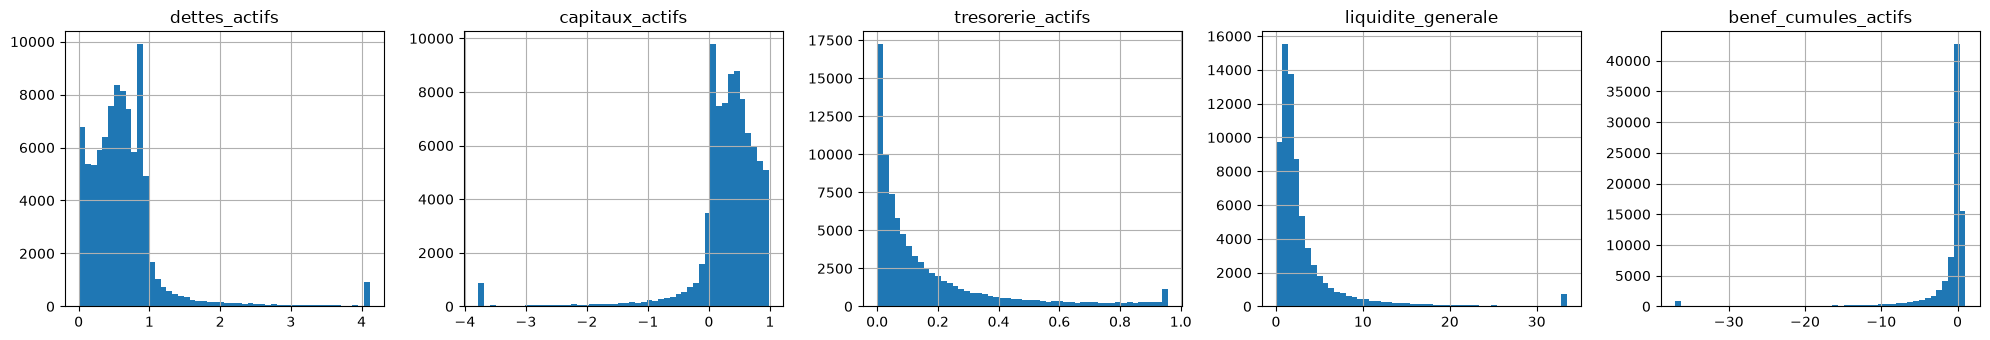

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, ratios):
    s = r[col].dropna()
    s.clip(s.quantile(.01), s.quantile(.99)).hist(bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

In [18]:
w = w.sort_values(["cik", "end"]).reset_index(drop=True)
suivant = w.groupby("cik").shift(-1)          # la ligne de l'année suivante, même entreprise

ecart_suivant = (suivant["end"] - w["end"]).dt.days
paire_ok = ecart_suivant.between(330, 400)    # seulement les années consécutives

w["var_actifs"] = np.where(paire_ok, np.log(suivant["Assets"]) - np.log(w["Assets"]), np.nan)
print(f"Paires (t → t+1) valides : {paire_ok.sum():,} sur {len(w):,} bilans")

Paires (t → t+1) valides : 79,484 sur 92,836 bilans


In [19]:
v = w["var_actifs"].dropna()
print(f"Actifs en hausse : {(v > 0).mean():.1%}")
print(f"Actifs en baisse : {(v < 0).mean():.1%}")
print(f"Actifs inchangés : {(v == 0).mean():.1%}")

Actifs en hausse : 62.0%
Actifs en baisse : 38.0%
Actifs inchangés : 0.0%


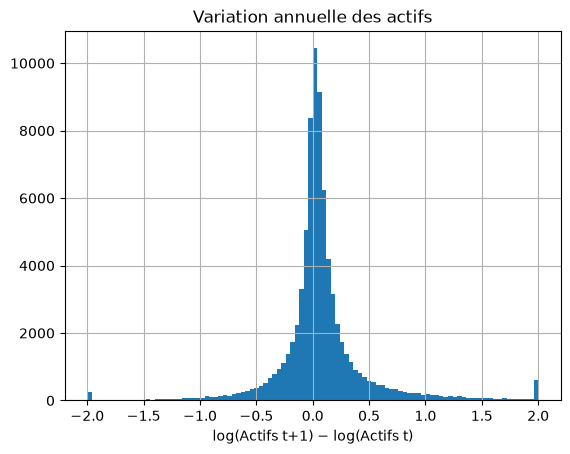

Actifs multipliés par plus de 2 : 5.8%
Actifs divisés par plus de 2    : 2.6%
0.01   -1.182
0.05   -0.453
0.25   -0.054
0.50    0.036
0.75    0.153
0.95    0.774
0.99    1.740
Name: var_actifs, dtype: float64


In [20]:
v.clip(-2, 2).hist(bins=100)
plt.xlabel("log(Actifs t+1) − log(Actifs t)"); plt.title("Variation annuelle des actifs"); plt.show()

print(f"Actifs multipliés par plus de 2 : {(v > np.log(2)).mean():.1%}")
print(f"Actifs divisés par plus de 2    : {(v < -np.log(2)).mean():.1%}")
print(v.quantile([.01, .05, .25, .5, .75, .95, .99]).round(3))

In [21]:
precedent = w.groupby("cik").shift(1)
ecart_prec = (w["end"] - precedent["end"]).dt.days
w["var_actifs_passee"] = np.where(ecart_prec.between(330, 400),
                                  np.log(w["Assets"]) - np.log(precedent["Assets"]), np.nan)

ok = w[["var_actifs_passee", "var_actifs"]].dropna()
print("Corrélation variation passée / variation future :", round(ok.corr().iloc[0, 1], 3))
same_sign = (np.sign(ok["var_actifs_passee"]) == np.sign(ok["var_actifs"])).mean()
print(f"Même sens que l'année précédente : {same_sign:.1%}")

Corrélation variation passée / variation future : 0.077
Même sens que l'année précédente : 65.2%


In [22]:
print("Corrélation de Spearman :", round(ok.corr(method="spearman").iloc[0, 1], 3))

Corrélation de Spearman : 0.244


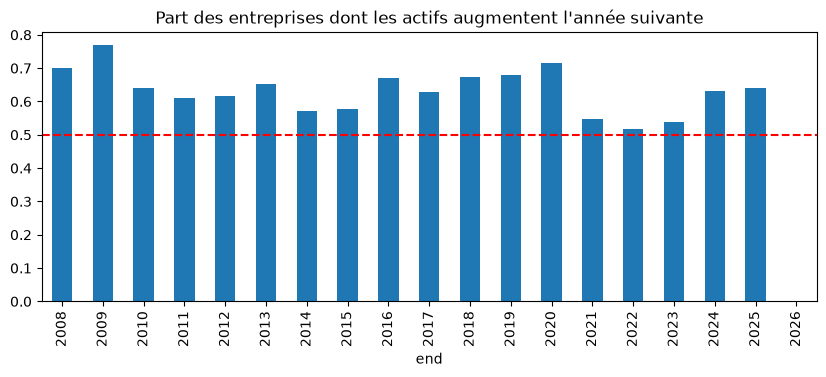

In [23]:
hausse_par_an = w.groupby(w["end"].dt.year)["var_actifs"].apply(lambda s: (s.dropna() > 0).mean())
hausse_par_an.plot.bar(figsize=(10, 3.5))
plt.axhline(0.5, color="red", linestyle="--")
plt.title("Part des entreprises dont les actifs augmentent l'année suivante"); plt.show()

In [24]:
for seuil in [1e5, 1e6, 1e7]:
    print(f"Actifs ≥ {seuil:,.0f} $ : {(w['Assets'] >= seuil).mean():.1%} des bilans gardés")

Actifs ≥ 100,000 $ : 100.0% des bilans gardés
Actifs ≥ 1,000,000 $ : 100.0% des bilans gardés
Actifs ≥ 10,000,000 $ : 90.1% des bilans gardés
